# DATASCI 185 · Quiz 3 复习 Cheat Sheet

参考上一份 Quiz 2 cheat sheet 的结构，根据 **practice_quiz_3 A–F、Lecture 9–12、Lab 5** 整理。每节都有 syntax、可运行例子和解释。这是按现有 practice 标注范围整理的复习材料；不额外假定 Lecture 13–15 属于本次范围。

## 快速查找：有思路，不知道怎么写？

| 我想做什么 | 找哪节 | 核心 syntax |
|---|---|---|
| 用名字查资料，再查出生年份 | 1 | `roster[name]["year"]` |
| 找最老、最年轻、最高分，并保留名字 | 2 · A | 循环比较，同时更新数值和名字 |
| 每天跨多个城市算平均 | 3 · B | 外层 day，内层 city，每天重置 total |
| 不知道用 len 还是 size | 4 | 字典项数 `len(d)`；数组总元素 `a.size` |
| 写 function，传入参数，拿回结果 | 5 | `def f(x): ... return result` |
| 输出 None，不知道为什么 | 6 | 检查 return 和缩进；print 不等于 return |
| 把 while 计算变成函数 | 7 · C | 初始化在函数内，return 在循环外 |
| 接收两个结果，或接收一个向量 | 8 | `a, b = f(...)`；注意最外层元素数量 |
| 写短函数、布尔判断、四舍五入 | 9 | `fn = lambda x: round(expression, 1)` |
| 对表格一列应用函数 | 10 · D | `df["column"].apply(function)` |
| 统计及格人数、复制表再换一列 | 10 | 布尔 Series `.sum()`；`df.copy()` |
| 遇到缺 key 或坏数字继续处理 | 11 | `try: ... except KeyError: ...` |
| 订单逐项计算，只跳过坏项目 | 12 · E | total 在 for 前，return 在 for 后 |
| 收集和验证 input | 13 | `int(input(...))` + try/except + 范围检查 |
| 强制某参数写名字、转换极坐标 | 14 · F | `def f(p1, p2, *, polar=False):` |
| 接收任意数量的位置／关键词参数 | 15 · Lab 5 | `*args` 是 tuple；`**kwargs` 是 dict |
| 函数改变原列表？局部／全局变量？ | 16 | 修改内容 vs 重新赋值 |
| 题目里哪些词对应哪种代码 | 17 | at least → >=；skip → continue |

**时间少的顺序：先看 2、3、6、10、12、14，再看 9 和 15。**

使用方法：选择带 NumPy、pandas、Matplotlib 的 Python kernel，可从上到下 Run All。会故意报错的反例以注释或捕获后打印的方式展示，因此完整运行不会被中断。

In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

## 1. Dictionary：key、value 和两步查找｜Lecture 9

Syntax：`字典[key]`。字典不是按照位置取值，而是按照你定义的 key 取值。

先看一个两层字典：外层 key 是姓名，外层 value 是这个人的资料；资料本身也是字典。

In [2]:
study_group = {
    "Abed": {"month": "March", "day": 23, "year": 2007},
    "Britta": {"month": "July", "day": 14, "year": 1998},
    "Pierce": {"month": "December", "day": 30, "year": 1962},
}

print(study_group["Pierce"])          # 整份内部字典
print(study_group["Pierce"]["year"])  # 1962
print(study_group["Abed"]["month"])   # March

{'month': 'December', 'day': 30, 'year': 1962}
1962
March


**你最容易混淆的一点：直接遍历 dictionary，得到的是外层 key。** 变量叫 people、name、i 都不改变这一点。

In [3]:
for name in study_group:
    print(name)                       # Abed / Britta / Pierce
    print(study_group[name]["year"])  # 每个人的出生年份

Abed
2007
Britta
1998
Pierce
1962


| 表达式 | 当 name="Pierce" 时的内容 | 类型 |
|---|---|---|
| `name` | `"Pierce"` | str |
| `study_group[name]` | `{"month": ..., "day": ..., "year": ...}` | dict |
| `study_group[name]["year"]` | `1962` | int |

所以 `name["year"]` 不对：name 是字符串。内部字典也没有 `"name"` 这个 key；姓名就在外层 key 中。

**keys、values、更新和新增：**

In [4]:
print(list(study_group.keys()))  # ['Abed', 'Britta', 'Pierce']
print(type(study_group.keys()))  # dict_keys：不是普通 list

skill_scores = {"Abed": 3.24, "Britta": 1.51}
print(list(skill_scores.values()))  # [3.24, 1.51]
skill_scores["Abed"] = skill_scores["Abed"] + 2
skill_scores["Todd"] = 9.99        # 新 key 会被添加
print(skill_scores)
print("Todd" in skill_scores)      # True：字典的 in 检查 key
print("todd" in skill_scores)      # False：区分大小写

['Abed', 'Britta', 'Pierce']
<class 'dict_keys'>
[3.24, 1.51]
{'Abed': 5.24, 'Britta': 1.51, 'Todd': 9.99}
True
False


需要 shuffle 字典的名字时，先创建 list。shuffle 改变 list 的顺序，不会改变字典本身。

In [5]:
names = list(skill_scores.keys())
random.shuffle(names)
print(names)
# 不要 names = random.shuffle(names)：shuffle 返回 None。

['Britta', 'Todd', 'Abed']


## 2. Running minimum / maximum：最值和姓名一起更新｜Practice A

找最老的人 = 找**最小出生年份**，而不是最大的年份。题目给定 `oldest_year=3000`，因为给定资料里的年份都比 3000 小。

每遇到更小的 year，同时更新 **year 和 name**。

In [6]:
oldest_year = 3000
oldest_name = "nobody"

for name in study_group:
    year = study_group[name]["year"]
    if year < oldest_year:
        oldest_year = year
        oldest_name = name

print(f"The oldest member is {oldest_name}, born in {oldest_year}")
# The oldest member is Pierce, born in 1962

The oldest member is Pierce, born in 1962


**为什么保存 `name` 而不是 `study_group[name]`？** 前者是姓名，后者是整份资料。若把整份资料存进 oldest_name，最后就会打印字典。

找最高分，用 `>`；给定成绩都非负时可以从 0 开始。

In [7]:
quiz_scores = {"Amy": 75, "Ben": 92, "Cindy": 88}
best_score = 0
best_name = "nobody"

for name in quiz_scores:
    score = quiz_scores[name]
    if score > best_score:
        best_score = score
        best_name = name

print(best_name, best_score)  # Ben 92

Ben 92


若数据可能全部是负数，最大值不能从 0 开始。对于非空资料，可以从**第一个真实值**开始。题目若明确给初始化值，按题目写。

In [8]:
penalty_scores = {"Amy": -8, "Ben": -3, "Cindy": -6}
first_name = list(penalty_scores.keys())[0]
best_name = first_name
best_score = penalty_scores[first_name]

for name in penalty_scores:
    if penalty_scores[name] > best_score:
        best_score = penalty_scores[name]
        best_name = name
print(best_name, best_score)  # Ben -3

Ben -3


比较用 `<` / `>` 时，相同最值会保留第一个遇到的人；用 `<=` / `>=` 会更新为最后一个遇到的人。Practice A 明确最老者出生年份唯一，不需要比较月份与日期。

## 3. 嵌套循环：每天跨多个城市算平均｜Practice B

任务：每一天，收集所有选中城市当天的温度，然后求平均。

**外层 day：决定现在算哪天。内层 city：把这一天各城市的温度加起来。**

`total=0` 在外层循环里面、内层循环之前；`average` 在内层结束后；分母使用实际选中的城市数。

In [9]:
cities_to_be_averaged = {
    "Atlanta": {"Monday": 78, "Tuesday": 81},
    "Savannah": {"Monday": 84, "Tuesday": 86},
    "Athens": {"Monday": 76, "Tuesday": 79},
}
days_of_week = ["Monday", "Tuesday"]

for day in days_of_week:
    total = 0
    for city in cities_to_be_averaged:
        total = total + cities_to_be_averaged[city][day]
    average = round(total / len(cities_to_be_averaged), 2)
    print(f"Average high on {day}: {average} °F")
# Monday: 79.33；Tuesday: 82.0

Average high on Monday: 79.33 °F
Average high on Tuesday: 82.0 °F


逐步看 Monday：total 从 0 → 78 → 162 → 238，平均值为 `round(238/3, 2)`。

| 代码位置错误 | 会发生什么 |
|---|---|
| total=0 放在两个循环外 | Tuesday 又累计 Monday 的总温度 |
| total=0 放在内层 city 循环里 | 每个城市都清零，只留下最后一个城市 |
| 除以固定的 3 | 随机选中 2 或 4 个城市时出错 |
| print 放在内层循环里 | 每个城市都会打印一次不完整结果 |

**换一个场景仍是同一结构：** 每个商品跨多家商店算均价，外层是 product，内层是 shop。题目若要求跨城市，就不能把每天的温度混在一起。

## 4. len、size、round 和输出小数

`len(x)` 数最外层项目数。字典数 key，list 数元素，字符串数字符。`.size` 是 NumPy array / pandas 对象的属性，普通 list 和 dict 没有这个属性。

In [10]:
print(len(cities_to_be_averaged))  # 3 个城市，不是 6 个温度
print(len([10, 20, 30]))          # 3
print(len("Abed"))                # 4

a = np.array([[1, 2, 3], [4, 5, 6]])
print(len(a))  # 2：两行
print(a.size)  # 6：总元素数
# len 是函数，要 ()；size 是属性，没有 ()。

3
3
4
2
6


课上使用 `round(数值, 小数位数)`。它返回一个数值，不保证打印时补零。

In [11]:
print(round(79.333333, 2))  # 79.33
print(round(82.0, 2))       # 82.0：数值已精确，不会自动补成 82.00
print(round(92.1954, 1))    # 92.2

temperature = round(238 / 3, 2)
print(f"Average temperature: {temperature} °F")

79.33
82.0
92.2
Average temperature: 79.33 °F


补充显示语法（不依赖它也能完成 practice 的四舍五入）：`f"{value:.2f}"` 强制显示两位，例如 82.00。此前检查的 lecture 中未找到这种写法示例；复习优先使用你熟悉的 round。

## 5. Function：定义、调用、参数和返回值｜Lecture 10

```python
def 函数名(参数1, 参数2):
    计算步骤
    return 结果

结果变量 = 函数名(输入1, 输入2)
```

`def` 只定义流程；要调用才运行函数体。参数是函数接受输入时使用的名字。

In [12]:
def add_numbers(x, y):
    answer = x + y
    return answer

# 运行定义本身不会打印任何内容。
result = add_numbers(2, 5)
print(result)  # 7
print(add_numbers(10, 3))  # 13
print(add_numbers(x=4, y=6))  # 10

7
13
10


**关键词传参**和**位置传参**都可以（除非定义限制 keyword-only）。关键词传参按名字对应；位置传参按顺序对应。参数名与外面变量名不必相同。

In [13]:
def final_value(P, r, n, t):
    return P * (1 + r/n)**(n*t)

principal = 100
rate = 0.01
print(round(final_value(principal, rate, 20, 10), 2))  # 110.51
print(round(final_value(t=10, P=100, n=20, r=0.01), 2))  # 110.51
# 1% 写 0.01；乘方写 **，不是 ^。

110.51
110.51


## 6. print、return、None 和缩进｜你最近的高频错误

`print`：在屏幕显示。`return`：把结果交给调用者，并立刻结束本次函数调用。

没有写 return，或者执行路径没有走到 return，就默认返回 None。

In [14]:
def only_print(x):
    print(x * 2)

result = only_print(3)  # 屏幕显示 6
print(result)          # None

def actually_return(x):
    return x * 2

result = actually_return(3)
print(result)          # 6

6
None
6


`print(function())` 会先运行函数，再打印它的返回值；函数里已有 print、又没 return，就可能先显示结果、再显示 None。

**return 放在循环哪里，决定什么时候结束：**

In [15]:
def sum_all(values):
    total = 0
    for value in values:
        total = total + value
    return total  # 与 for 对齐：全部加完后返回

print(sum_all([2, 3, 4]))  # 9
print(sum_all([]))         # 0

9
0


若把 return 缩进到循环里面，通常第一个元素处理完就结束。函数内的初始化也要在正确位置：`total=0` 放在 for 前，不要每轮都清零。

| 指令 | 作用 |
|---|---|
| return | 结束当前函数，并可返回结果 |
| break | 退出最近的一层 for/while，继续执行循环后代码 |
| continue | 跳过本轮剩余部分，进入最近一层循环的下一轮 |

break 不能代替 return；没有循环时写 break 会造成 SyntaxError。

## 7. 把 while 变成可重复调用的 function｜Practice C

固定初始人口 1000；达到 2000 停止。`growth_rate` 是每年增长率，0.01 表示 1%。

函数内重新初始化 population 和 years；每轮更新两者；return 放在 while 后面。

In [16]:
def years_to_double(growth_rate):
    population = 1000
    years = 0
    while population < 2000:
        population = population * (1 + growth_rate)
        years = years + 1
    return years

for rate in [0.01, 0.02, 0.05, 0.10]:
    print(years_to_double(rate))
# 70、36、15、8

70
36
15
8


判断“达到或超过目标就停”，循环条件用 `< target`。如果要求“严格超过才停”，循环条件会是 `<= target`。不要机械套符号，要问：什么时候还需要继续？

这个例子假设增长率为正。考试给定的 1%、2%、5%、10% 都符合；不要传入 0 导致永不翻倍。

## 8. 多个 return 值、tuple 和拆分｜Lecture 10

`return a, b` 返回一个包含两项的 tuple。接收时可用两个变量，也可用一个变量保存整个 tuple。

In [17]:
def sum_and_difference(x, y):
    return x + y, x - y

total, difference = sum_and_difference(8, 3)
print(total, difference)  # 11 5

both = sum_and_difference(8, 3)
print(both)       # (11, 5)
print(both[0])    # 11

11 5
(11, 5)
11


**最外层数量要匹配。** 返回“一个数组 + 一个数”仍然是两个对象，不能直接用四个普通变量接住。创建 NumPy 数组时，先用列表把各分量放在一起。

In [18]:
def vector_and_divergence(x, y, z):
    vector = np.array([x*np.exp(y), np.exp(x*y), np.sin(y*z)])
    divergence = np.exp(y) + x*np.exp(x*y) + y*np.cos(y*z)
    return vector, divergence

vector, divergence = vector_and_divergence(1, 2, 3)
v1, v2, v3 = vector
print(vector)
print(divergence)
# a, b, c, d = vector_and_divergence(1, 2, 3)  # ValueError：最外层只有两项
# np.array(v1, v2, v3)  # 不对：这是三个独立参数
# np.array([v1, v2, v3])  # 对：把一个列表转成数组

[ 7.3890561  7.3890561 -0.2794155]
16.69845277116203


若后面的代码固定 `root1, root2 = function(...)`，函数每个分支都应返回可拆成两项的结果。`return None` 不能被拆成两项；`return None, None` 可以。

## 9. lambda：一行函数、布尔判断和 round｜Lecture 11

Syntax：`函数名 = lambda 参数: 表达式`。冒号后是自动返回的表达式，不写 return。

先和你熟悉的 def 对照：

In [19]:
def square_def(x):
    return x**2

square = lambda x: x**2
print(square_def(3))  # 9
print(square(3))      # 9

fn_sum = lambda x, y, z: x + y + z
print(fn_sum(5, 3, 12))  # 20

9
9
20


**比较表达式本身就是 True / False。** 不必再写 if/else，但你喜欢显式写也可以。

In [20]:
is_pass = lambda grade: grade >= 55
is_pass_explicit = lambda grade: True if grade >= 55 else False

print(is_pass(55))           # True
print(is_pass(54))           # False
print(is_pass_explicit(55))  # True

# Lecture 11 原例子的结构：
fn_beats = lambda skill, benchmark: skill > benchmark
print(fn_beats(6.72, 6.72))   # False：strictly greater 才是 True

True
False
True
False


lambda 带条件时顺序是：`成立时的结果 if 条件 else 不成立时的结果`。若题目要求字符串，就返回字符串；要求 Boolean，就返回 True/False。

**公式计算 + 保留小数：**

In [21]:
curve_grade = lambda old_grade: round(10 * np.sqrt(old_grade), 1)
print(curve_grade(85))  # 92.2

# 长表达式可以用括号换行，仍然是一个表达式：
curve_grade_long = lambda old_grade: (
    round(10 * np.sqrt(old_grade), 1)
)
print(curve_grade_long(45))  # 67.1

92.2
67.1


有循环、多个赋值或多步流程时，用 def。lambda 的名字没有特殊含义：参数叫 grade、x、old_grade 都行，只要冒号前后对应。

## 10. pandas .apply()、Series 和人数统计｜Practice D

**固定方向：`要处理的一列.apply(函数名)`。**

不是 `函数.apply(表格)`，也不是 `.apply(函数名())`。Series 会逐个取值，替你把输入传给函数。

题目要求 if/else，就使用 if/else；即使能用 lambda 简写，也不要遗漏指定方法。

In [22]:
df_grades = pd.DataFrame({
    "name": ["Chang", "Duncan", "Craig", "Vicki", "Garrett"],
    "numeric_grade": [85, 90, 45, 75, 50]
})

def check(numeric_grade):
    if numeric_grade >= 55:
        return "status = pass"
    else:
        return "status = fail"

statuses = df_grades["numeric_grade"].apply(check)
display(statuses)
# pass、pass、fail、pass、fail

0    status = pass
1    status = pass
2    status = fail
3    status = pass
4    status = fail
Name: numeric_grade, dtype: str

执行过程：`check(85)`、`check(90)`、`check(45)`……结果组成一列 Series。

| 对象 | 含义 |
|---|---|
| df_grades | DataFrame：整张表 |
| df_grades["numeric_grade"] | Series：原成绩一列 |
| check | 函数本身，交给 apply 使用 |
| check(85) | 立刻调用函数，得到字符串 |
| statuses | apply 后得到的一列新结果 |

**原表不会因为这一句 apply 自动改变。** Series 也是 object，不是普通 list。

In [23]:
student_info = df_grades.copy()
curved_grades = student_info["numeric_grade"].apply(curve_grade)
curved_grades.name = "curved_grade"

display(curved_grades)
print(type(curved_grades))  # pandas Series
print(list(curved_grades))  # [92.2, 94.9, 67.1, 86.6, 70.7]

0    92.2
1    94.9
2    67.1
3    86.6
4    70.7
Name: curved_grade, dtype: float64

<class 'pandas.Series'>
[92.2, 94.9, 67.1, 86.6, 70.7]


`.name` 给 Series 命名，不会自动把它加入原表。只想打印数字列表时，打印 `list(series)`；原 Series 不会改变类型。

**True 算 1，False 算 0，所以 sum 可以数人数。**

In [24]:
grade_check = lambda grade: grade >= 55
before_check = student_info["numeric_grade"].apply(grade_check)
after_check = curved_grades.apply(grade_check)

print(list(before_check))    # [True, True, False, True, False]
print(before_check.sum())    # 3
print(after_check.sum())     # 5
print(np.sum(before_check))  # 3：也可以用课上的 np.sum

[True, True, False, True, False]
3
5
3


**想保留整张表，只改新表里的成绩列：**

In [25]:
new_student_info = student_info.copy()
new_student_info["numeric_grade"] = curved_grades
display(new_student_info)
print(list(student_info["numeric_grade"]))  # 原表仍然是 [85, 90, 45, 75, 50]

,name,numeric_grade
0,Chang,92.2
1,Duncan,94.9
2,Craig,67.1
3,Vicki,86.6
4,Garrett,70.7


[85, 90, 45, 75, 50]


## 11. try / except：认识报错并指定处理方式｜Lecture 12

try 从上到下执行；某一行出错，立刻跳过 try 的剩余代码，进入匹配的 except。不要把报错代码放在 try 外面，又指望 except 接住。

| 类型 | 发生原因 | 例子 |
|---|---|---|
| KeyError | 字典没有这个 key | `prices["kiwi"]` |
| ValueError | 转换的内容不合法 | `int("lots")`、`int("2.5")` |
| TypeError | 类型不适合操作 | `"Todd" + 9.99` |
| IndexError | 列表位置不存在 | `[10,20][5]` |
| NameError | 名字没有定义 | 使用从未创建的变量 |
| UnboundLocalError | 读到尚未赋值的局部变量 | total 未初始化就 `total = total + ...` |
| ZeroDivisionError | Python 数值除以 0 | `5 / 0` |
| SyntaxError | 代码语法不合法 | if / for 行少冒号 |

UnboundLocalError 属于 NameError 的一种。语法错误通常要先改代码；一般不是在同一个不合法 cell 里加 try 就能解决。

In [26]:
prices = {"apple": 0.50, "banana": 1.25, "cherry": 3.00}

try:
    price = prices["kiwi"]
except KeyError:
    print("Sorry, we don't sell kiwi")

try:
    quantity = int("lots")
except ValueError:
    print("Sorry, lots isn't a valid quantity")

Sorry, we don't sell kiwi
Sorry, lots isn't a valid quantity


`"4"` 是字符串，`int("4")` 才是整数 4；不是所有看上去像数字的字符串都能用 int：`int("2.5")` 不行。不要为这道“whole number”题先 float 再 int，那会把 2.5 截成 2，改变题意。

In [27]:
order = {"apple": "4"}
item = "apple"
print(order[item])        # 打印为 4，但原类型是 str
print(type(order[item]))  # str
quantity = int(order[item])
print(type(quantity))     # int
print(prices[item] * quantity)  # 2.0

4
<class 'str'>
<class 'int'>
2.0


`except:` 会接住太多种错误，可能把拼写错误也隐藏掉。题目要求 KeyError / ValueError 时，分别写清楚类型。

NumPy 对某些无效数值操作会给出 RuntimeWarning 并返回 nan；warning 与抛出 exception 不同。不要以为写 except 就会自动捕获所有 warning。

## 12. 完整订单模板：只计算有效项目｜Practice E

每个商品先查价格，再把数量字符串转成整数，两个步骤成功后才加总价。

**计算放在 try 里面的版本：**

In [28]:
def order_total(order, prices):
    total = 0
    for item in order:
        try:
            price = prices[item]
            quantity = int(order[item])
            total = total + price * quantity
        except KeyError:
            print(f"Sorry, we don't sell {item}")
        except ValueError:
            print(f"Sorry, {order[item]} isn't a valid quantity")
    return total

prices = {"apple": 0.50, "banana": 1.25, "cherry": 3.00}
order = {"apple": "4", "kiwi": "2", "banana": "lots", "cherry": "1"}
print(order_total(order, prices))
# Sorry, we don't sell kiwi
# Sorry, lots isn't a valid quantity
# 5.0

Sorry, we don't sell kiwi
Sorry, lots isn't a valid quantity
5.0


**逐项追踪：**

| item | 查价格 | 转换数量 | 加到 total？ |
|---|---|---|---|
| apple | 0.50 | int("4") → 4 | +2.0 |
| kiwi | KeyError | 不执行 | 否 |
| banana | 1.25 | int("lots") → ValueError | 否 |
| cherry | 3.00 | int("1") → 1 | +3.0 |

为什么提示用 `order[item]`，不用 quantity？转换失败时，quantity 没有成功赋新值：它可能未定义，也可能残留上一个商品的数量。错误提示要显示用户原来输入的字符串。

**计算放在 except 后面的版本也可以，但异常分支必须跳过计算。** 这就是 continue 的用处：

In [29]:
def order_total_with_continue(order, prices):
    total = 0
    for item in order:
        try:
            price = prices[item]
            quantity = int(order[item])
        except KeyError:
            print(f"Sorry, we don't sell {item}")
            continue
        except ValueError:
            print(f"Sorry, {order[item]} isn't a valid quantity")
            continue
        total = total + price * quantity
    return total

print(order_total_with_continue(order, prices))  # 相同提示和 5.0

Sorry, we don't sell kiwi
Sorry, lots isn't a valid quantity
5.0


两个版本选一个记住即可。try 内已出错，就不会继续执行 try 里的计算；第二个版本把计算放在外面，因此需要 continue 避免误用旧变量。

**你之前出现的三个问题：** total 没有初始化；ValueError 提示使用未成功赋值的 quantity；漏掉 return 导致打印 None。检查四处缩进：def → total/for/return 同层 → try/except 同层 → 各自内容再缩进。

## 13. input、转换、重新询问与 raise｜Lecture 12

input 得到字符串。输入 20 也先得到 `"20"`，需要 int 或 float 才能算数。

以下定义了可交互函数；为避免 Run All 卡住，调用行先注释。你可以取消注释，试着输入 abc、-1、50、10。

In [30]:
def ask_for_N(num_candidates):
    while True:
        typed = input(f"Choose N from 0 to {num_candidates - 1}: ")
        try:
            N = int(typed)
        except ValueError:
            print("Please enter a whole number.")
            continue
        if N < 0 or N >= num_candidates:
            print("Out of range.")
            continue
        return N

# N = ask_for_N(50)
# print(N)

转换成功不代表范围正确，所以 try/except 后还需要 if。题目要小数分数时用 `float()`；要整数次数时用 `int()`。

`raise` 是主动产生一个异常；`except` 是捕获异常。

In [31]:
def average_nonempty(values):
    if len(values) == 0:
        raise ValueError("Cannot average an empty list")
    return sum(values) / len(values)

print(average_nonempty([2, 4, 6]))  # 4.0
try:
    average_nonempty([])
except ValueError as error:
    print(error)  # Cannot average an empty list

4.0
Cannot average an empty list


## 14. 默认值、keyword-only 和坐标转换｜Practice F

```python
def f(a, b, *, option=False):
    ...
```

`a`、`b` 可以按位置传入；`*` 后的 option 必须写名字。默认 False 表示不传 option 时就用 False。

Lab 5 的生日例子：

In [32]:
def birthday(month, day, *, name=None):
    if name is None:
        print(f"Your birthday is {month} {day}.")
    else:
        print(f"{name}, your birthday is {month} {day}.")

birthday("June", 20)
birthday("June", 20, name="Peter")
birthday(day=20, month="June", name="Peter")
# birthday("June", 20, "Peter")  # TypeError：name 必须写名字
# birthday(month="June", 20)     # SyntaxError：位置参数不能跟在普通关键词参数后面

Your birthday is June 20.
Peter, your birthday is June 20.
Peter, your birthday is June 20.


要每个参数都写名字，把 `*` 放在最前面：

In [33]:
def named_birthday(*, month, day):
    return f"{month} {day}"

print(named_birthday(month="June", day=20))
# named_birthday("June", 20)  # TypeError

June 20


**Practice F：一个函数处理两种坐标。**

- 默认：p1、p2 各自是直角坐标 `(x, y)`。
- `polar=True`：它们各自是极坐标 `(r, theta)`；角度是弧度。
- 极坐标先转换：`x=r*cos(theta)`、`y=r*sin(theta)`，再调用距离函数。

距离公式：`sqrt((x1-x2)**2 + (y1-y2)**2)`。不要忘记 return，也不要只转换一个点。

In [34]:
def euclidean_dist(p1, p2):
    x1, y1 = p1
    x2, y2 = p2
    return np.sqrt((x1-x2)**2 + (y1-y2)**2)

def cord_dist(p1, p2, *, polar=False):
    if polar:
        r1, theta1 = p1
        r2, theta2 = p2
        p1 = (r1*np.cos(theta1), r1*np.sin(theta1))
        p2 = (r2*np.cos(theta2), r2*np.sin(theta2))
    return euclidean_dist(p1, p2)

print(cord_dist((0, 0), (3, 4)))  # 5.0
print(cord_dist((2, 0), (2, np.pi), polar=True))  # 4.0
print(cord_dist((1, 2), (1, 2)))  # 0.0：同一个点
# cord_dist((2, 0), (2, np.pi), True)  # TypeError

5.0
4.0
0.0


这里 `np.cos`、`np.sin`、`np.sqrt` 都来自 NumPy，所以写 `np.`。`import numpy as np` 没有单独创建名为 sin 的函数。角度对应：0、π/2、π 分别是 0°、90°、180°。

## 15. *args、**kwargs 和函数的输入打包｜Lab 5

三个星号语法不要混淆：

| 定义形式 | 意思 | 得到什么 |
|---|---|---|
| `def f(a, *, flag=False)` | 单独 *：后面的参数 keyword-only | flag 是传入的值 |
| `def f(*args)` | 收集任意数量的位置参数 | args 是 tuple |
| `def f(**kwargs)` | 收集任意数量的关键词参数 | kwargs 是 dict |

名称 args / kwargs 是惯例，星号才决定作用。

In [35]:
def show_args(*args):
    print(args)
    print(type(args))
    print(len(args))

show_args("hello", [1, 2], 6)  # ('hello', [1, 2], 6)，tuple，3
show_args()                    # ()，tuple，0

('hello', [1, 2], 6)
<class 'tuple'>
3
()
<class 'tuple'>
0


args 是 tuple，所以取第四个参数用 `args[3]`，不是 args[4]。数量不足就会 IndexError，可以先检查 len。

In [36]:
def show_fourth(*args):
    if len(args) >= 4:
        print(args[3])
    else:
        print("Not enough arguments")

show_fourth(10, 20, 30, 40, 50)  # 40
show_fourth(10, 20)              # Not enough arguments
show_fourth()                    # Not enough arguments

40
Not enough arguments
Not enough arguments


**kwargs 把参数名字变成 key：**

In [37]:
def introduce(**kwargs):
    if "name" in kwargs:
        if "major" in kwargs:
            return f"Hi, I'm {kwargs['name']} and I'm majoring in {kwargs['major']}!"
        else:
            return f"Hi, I'm {kwargs['name']}!"
    else:
        return "Hi!"

print(introduce(name="Annie", major="Data Science"))
print(introduce(name="Annie"))
print(introduce(major="Physics"))  # Hi!
print(introduce())                 # Hi!

Hi, I'm Annie and I'm majoring in Data Science!
Hi, I'm Annie!
Hi!
Hi!


可选绘图设置：一个有 name 的关键词参数会进入 kwargs，只有写了使用它的代码才会生效。

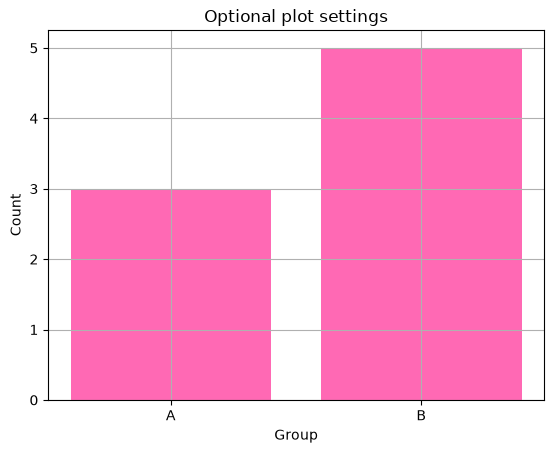

In [38]:
def make_bar_plot(categories, heights, **kwargs):
    plt.figure()
    if "color" in kwargs:
        plt.bar(categories, heights, color=kwargs["color"])
    else:
        plt.bar(categories, heights)
    if "grid" in kwargs:
        if kwargs["grid"]:
            plt.grid()
    plt.xlabel("Group")
    plt.ylabel("Count")
    plt.title("Optional plot settings")
    plt.show()

make_bar_plot(["A", "B"], [3, 5], color="hotpink", grid=True)

`print` 也接收多个位置参数；`sep` 是指定分隔符的关键词，不是要打印的额外项目。

In [39]:
print("Port", "au", "Prince, Haiti", sep="-")  # Port-au-Prince, Haiti
print("score:", 95, "passed:", True, sep="*")   # score:*95*passed:*True
print("score:", 95, "passed:", True, "*")       # 星号成为最后一个打印项目

Port-au-Prince, Haiti
score:*95*passed:*True
score: 95 passed: True *


## 16. Local/global、函数改变输入、无返回值｜Lecture 10–11

参数和函数内创建的变量都是 local。即使 return 了它们的值，变量名也不会自动成为 global。调用者可以用另外的名字保存返回值。

In [40]:
global_bonus = 2

def boosted_score(score):
    answer_inside = score + global_bonus
    return answer_inside

outside_result = boosted_score(5)
print(outside_result)  # 7
# print(answer_inside)  # NameError：它是局部名字
# score 这个参数也是 local；global_bonus 是读取的全局变量。

7


**修改传入 list 的内容**会影响调用者看到的同一个 list；**给局部变量重新赋一个新 list**不会改变外面的变量指向。

In [41]:
def append_in_place(values):
    values.append("new")

def assign_new_list(values):
    values = values + ["new"]

original_a = [1, 2]
append_in_place(original_a)
print(original_a)  # [1, 2, 'new']

original_b = [1, 2]
assign_new_list(original_b)
print(original_b)  # [1, 2]

[1, 2, 'new']
[1, 2]


若希望不改变原列表，又把新列表交出来，可以复制再返回：

In [42]:
def appended_copy(values):
    new_values = values.copy()
    new_values.append("new")
    return new_values

old_values = [1, 2]
new_values = appended_copy(old_values)
print(old_values)  # [1, 2]
print(new_values)  # [1, 2, 'new']

[1, 2]
[1, 2, 'new']


**画图函数不一定需要返回值。** 它的任务是显示图；不要为了有 return 把所有函数都写成返回某个数字。

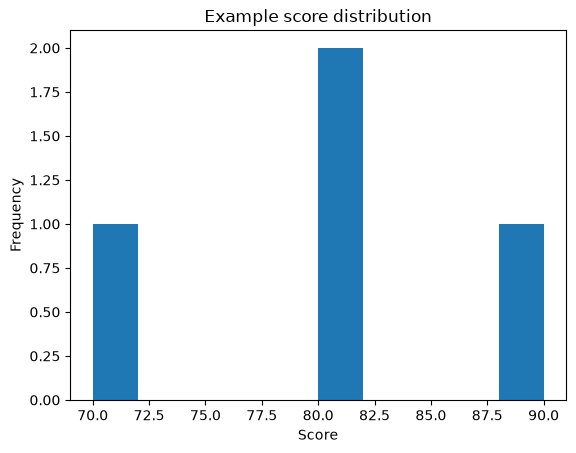

In [43]:
def labeled_histogram(values, xlabel, title):
    plt.figure()
    plt.hist(values)
    plt.xlabel(xlabel)
    plt.ylabel("Frequency")
    plt.title(title)
    plt.show()

labeled_histogram([70, 80, 80, 90], "Score", "Example score distribution")
# 函数没有显式 return，默认返回 None；显示图这个动作已经完成。

## 17. 最后自查：把题目语言翻译成代码

| 题目说 | 代码要点 |
|---|---|
| at least 55 | `grade >= 55`，一定测试 55 |
| strictly greater / beats | `skill > benchmark`，相等是 False |
| oldest person | 最小出生年份，姓名和年份一起更新 |
| across selected cities | 只遍历 selected 的字典，不能偷偷算全部城市 |
| average on each day | total 每天清零，除以实际城市数 |
| write a function that returns | def + return；仅 print 不够 |
| apply to the numeric_grade column | `df["numeric_grade"].apply(function)` |
| use try/except, not if | 用查字典／int 转换触发并捕获对应异常 |
| skip invalid item | continue，或把计算全部放进 try 内 |
| keyword-only polar=False | `def f(p1, p2, *, polar=False):` |
| tuple representing a point | `x, y = p`，或 `p[0]`、`p[1]` |

### 你考前最值得检查的 12 件事

1. `for name in dictionary` 得到 key；取内部资料要写 `dictionary[name]`。
2. 保存名字写 `oldest_name = name`，不是把整份字典存进去。
3. 最值循环同时更新名字和值；找最老用 `<`。
4. 嵌套循环的 total 每组重置，平均数分母不写死。
5. 定义函数后要调用；改函数后要重新运行定义所在的 cell。
6. None 先查有没有 return、是否在循环内过早 return、某条分支是否没 return。
7. `.apply()` 是一列调用，不是函数调用；括号里只写函数名。
8. 布尔值 True/False 不加引号；`"False"` 是非空字符串，不等于 False。
9. `quantity = int(order[item])` 失败时，提示用原始 `order[item]`。
10. total 在 for 前初始化，return 在 for 后；不要用旧 price/quantity 算坏项目。
11. keyword-only 的实参写 `polar=True`；极坐标转换两个点，角度用弧度。
12. 用边界值、空列表／空订单、无效项在第一位等情况自测，不只看一次随机结果。

### 两分钟口头自测

- key 和 value 在嵌套字典里各是什么？
- 两个城市时，我的平均数代码会自动除以 2 吗？
- 为什么 return years 要与 while 对齐？
- 为什么 `.apply(check())` 一般不对？
- 为什么 except 里面不能拿刚刚转换失败的 quantity 打印？
- `*`、`*args`、`**kwargs` 分别做什么？
- `return None` 与 `return None, None` 为什么不能互换？

答案都在上面的完整例子中；先尝试自己说出原因，再回对应章节核对。